# ANALYSIS FORECAST

In [133]:
import sys
from py_eddy_tracker.appli.grid import eddy_id
from py_eddy_tracker.dataset.grid import RegularGridDataset
from py_eddy_tracker.generic import distance_grid
from datetime import datetime
import glob
from netCDF4 import Dataset
import re
import pandas as pd
import os
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import cm
from datetime import datetime, timedelta
from py_eddy_tracker import data
from py_eddy_tracker.observations.observation import EddiesObservations
from py_eddy_tracker.observations.tracking import TrackEddiesObservations
#from py_eddy_tracker import py_eddy_tracker_sample

# Graphics
#matplotlib inline
import matplotlib.ticker as mticker
import matplotlib.pyplot as plt
import matplotlib
font = {'family' : 'serif',
        'weight' : 'bold',
        'size'   : 14}
matplotlib.rc('font', **font)

%reload_ext autoreload

In [136]:
# Initial start_date
start_date = datetime.strptime("20230510", "%Y%m%d")

input_dirs = [
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_0/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_1/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_2/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_3/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_4/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_5/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_6/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_7/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_8/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_9/',

]

# Define empty lists to store the results for each input directory
Nb_F0=[]
Nb_F1=[]
Nb_F2=[]
Nb_F3=[]
Nb_F4=[]
Nb_F5=[]
Nb_F6=[]
Nb_F7=[]
Nb_F8=[]
Nb_F9=[]
Nb_ANA=[]

Rad_F0=[]
Rad_F1=[]
Rad_F2=[]
Rad_F3=[]
Rad_F4=[]
Rad_F5=[]
Rad_F6=[]
Rad_F7=[]
Rad_F8=[]
Rad_F9=[]
Rad_ANA=[]

for idx, input_dir in enumerate(input_dirs, start=1):
    for i in range(37):
        date = start_date + timedelta(days=i)
    
        date_str = date.strftime("%Y%m%d")

        obs_file_a = input_dir + f"Anticyclonic_GLO12_FC0_{date_str}.nc"
        obs_data_a = EddiesObservations.load_file(obs_file_a)
        obs_file_c = input_dir + f"Cyclonic_GLO12_FC0_{date_str}.nc"
        obs_data_c = EddiesObservations.load_file(obs_file_c)

        try:
            obs_data_a = EddiesObservations.load_file(obs_file_a)
            obs_data_c = EddiesObservations.load_file(obs_file_c)
        except Exception as e:
            print(f"Error loading files for {date}: {e}")
            continue  # Skip to the next date if there's an error loading the files
        obs_eddies = obs_data_a.merge(obs_data_c)
        
        # Append the result to the corresponding list based on the input directory index
        if input_dir == input_dirs[0]:
            Nb_F0.append(len(obs_eddies))
            Rad_F0.append(obs_eddies.radius_e / 1000)
        elif input_dir == input_dirs[1]:
            Nb_F1.append(len(obs_eddies))
            Rad_F1.append(obs_eddies.radius_e / 1000)
        elif input_dir == input_dirs[2]:
            Nb_F2.append(len(obs_eddies) )
            Rad_F2.append(obs_eddies.radius_e / 1000)
        elif input_dir == input_dirs[3]:
            Nb_F3.append(len(obs_eddies)  )
            Rad_F3.append(obs_eddies.radius_e / 1000)
        elif input_dir == input_dirs[4]:
            Nb_F4.append(len(obs_eddies) )
            Rad_F4.append(obs_eddies.radius_e / 1000)
        elif input_dir == input_dirs[5]:
            Nb_F5.append(len(obs_eddies))
            Rad_F5.append(obs_eddies.radius_e / 1000)
        elif input_dir == input_dirs[6]:
            Nb_F6.append(len(obs_eddies))
            Rad_F6.append(obs_eddies.radius_e / 1000)
        elif input_dir == input_dirs[7]:
            Nb_F7.append(len(obs_eddies))
            Rad_F7.append(obs_eddies.radius_e / 1000)
        elif input_dir == input_dirs[8]:
            Nb_F8.append(len(obs_eddies))
            Rad_F8.append(obs_eddies.radius_e / 1000)
        elif input_dir == input_dirs[9]:
            Nb_F9.append(len(obs_eddies))
            Rad_F9.append(obs_eddies.radius_e / 1000)   


input_dir_analysis='/data/rd_exchange/fdubost/EddyDetection/FDUBOST/nrt/GLO12V4/Detect_eddies_2023_SE70/'
for i in range(37):
    date = start_date + timedelta(days=i)
    
    date_str = date.strftime("%Y%m%d")
    analyse_a  = input_dir_analysis + f"Anticyclonic_GLO12_{date_str}.nc"
    analyse_c  = input_dir_analysis + f"Cyclonic_GLO12_{date_str}.nc"


    obs_data_a = EddiesObservations.load_file(analyse_a)
    obs_data_c = EddiesObservations.load_file(analyse_c)
    obs_eddies = obs_data_a.merge(obs_data_c)
    

    Nb_ANA.append(len(obs_eddies))
    Rad_ANA.append(obs_eddies.radius_e / 1000)    

/tmp/ipykernel_1087993/3192457199.py:24: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_map = cm.get_cmap('viridis')


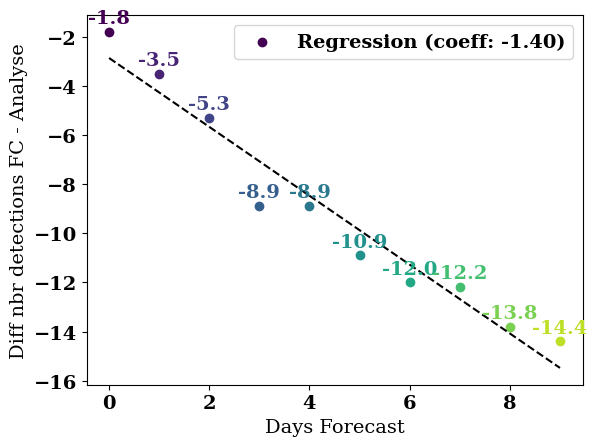

In [135]:
forecast_lists = [Nb_F0, Nb_F1, Nb_F2, Nb_F3, Nb_F4, Nb_F5, Nb_F6, Nb_F7, Nb_F8, Nb_F9]

differences = []
differences_pc = []
for forecast_list in forecast_lists:
    forecast_array = np.array(forecast_list)
    analyse_array = np.array(Nb_ANA)
    
    diff = np.subtract(forecast_array, analyse_array)
    
    diff_pc= (diff/analyse_array)*100
    differences_pc.append(diff_pc)
    differences.append(diff)

diff_mean= [round(np.nanmean(diff),1) for diff in differences]
diff_pc_mean= [round(np.nanmean(diff),1) for diff in differences_pc]
#for i, diff in enumerate(diffs_moyennes):
 #   print(f"Difference moyenne pour Nb_F{i} : {diff}")

plt.figure()

x = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

color_map = cm.get_cmap('viridis')

for i in range(len(x)):
    color = color_map(i/len(x))  # Color based on position of point
    plt.scatter(x[i], diff_mean[i], color=color)
    plt.text(x[i], diff_mean[i] + 0.2, str(np.round(diff_mean[i], 1)), ha='center', va='bottom', color=color)

# Calculate linear regression
coeffs = np.polyfit(x, diff_mean, 1)
regression_fn = np.poly1d(coeffs)

# Plot linear regression line
x_regression = np.linspace(min(x), max(x), 100)  # Generate x values for regression line
plt.plot(x_regression, regression_fn(x_regression), color='black', linestyle='--')

# Display coefficient of regression in legend
plt.legend(['Regression (coeff: {:.2f})'.format(coeffs[0])])

plt.xlabel("Days Forecast")
plt.ylabel("Diff nbr detections FC - Analyse")
plt.show()





/tmp/ipykernel_1087993/1663716721.py:5: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  color_map = cm.get_cmap('viridis')


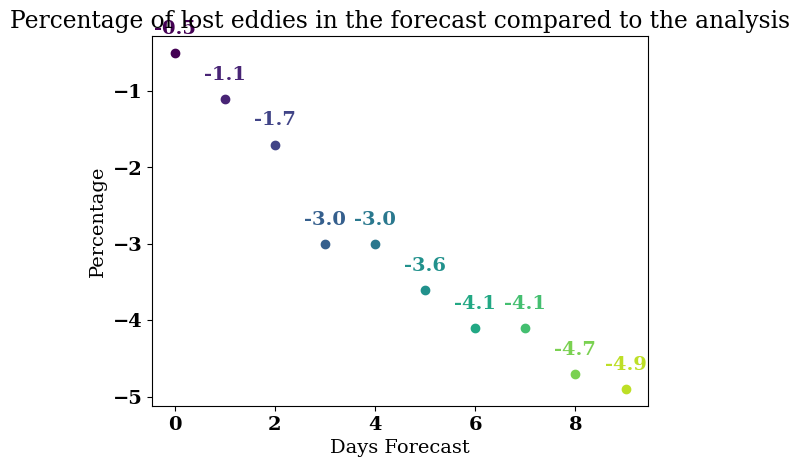

In [48]:
plt.figure()

x = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]

color_map = cm.get_cmap('viridis')

for i in range(len(x)):
    color = color_map(i/len(x))  # Color based on position of point
    plt.scatter(x[i], diff_pc_mean[i], color=color)
    plt.text(x[i], diff_pc_mean[i] + 0.2, str(np.round(diff_pc_mean[i], 1)), ha='center', va='bottom', color=color)


plt.xlabel("Days Forecast")
plt.ylabel("Percentage")
plt.title("Percentage of lost eddies in the forecast compared to the analysis")
plt.show()

### Compute cost function 

In [95]:


input_dir = '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/nrt/GLO12V4/Detect_eddies_2023_SE70/'
input_dirs_FC = [
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_0/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_1/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_2/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_3/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_4/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_5/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_6/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_7/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_8/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_9/',
]

# Initialize lists to store results for each forecast directory
results = {
    'AC': [[] for _ in input_dirs_FC],
    'CC': [[] for _ in input_dirs_FC],
    'MEAN': [[] for _ in input_dirs_FC]
}

start_date = datetime.strptime("20230510", "%Y%m%d")
num_days = 37

for i in range(num_days):
    # Date courante
    date = start_date + timedelta(days=i)
    date_str = date.strftime("%Y%m%d")
    print(date_str)
    
    # Path for the observation files for anticyclones and cyclones
    obs_file_AC = input_dir + f"Anticyclonic_GLO12_{date_str}.nc"
    obs_file_CC = input_dir + f"Cyclonic_GLO12_{date_str}.nc"
    
    # Load observation data
    obs_data_AC = EddiesObservations.load_file(obs_file_AC)
    obs_data_CC = EddiesObservations.load_file(obs_file_CC)

    for idx, input_dir_FC in enumerate(input_dirs_FC):
        # Path for the forecast files for anticyclones and cyclones
        fcst_file_AC = input_dir_FC + f"Anticyclonic_GLO12_FC0_{date_str}.nc"
        fcst_file_CC = input_dir_FC + f"Cyclonic_GLO12_FC0_{date_str}.nc"
        
        # Load forecast data
        fcst_data_AC = EddiesObservations.load_file(fcst_file_AC)
        fcst_data_CC = EddiesObservations.load_file(fcst_file_CC)
        
        # Calculate tracking and cost for anticyclones
        ref_id_AC, model_id_AC, cost_AC = obs_data_AC.tracking(fcst_data_AC)
        mean_cost_AC = np.mean(cost_AC)
        results['AC'][idx].append(mean_cost_AC)
        
        # Calculate tracking and cost for cyclones
        ref_id_CC, model_id_CC, cost_CC = obs_data_CC.tracking(fcst_data_CC)
        mean_cost_CC = np.mean(cost_CC)
        results['CC'][idx].append(mean_cost_CC)
        
        # Calculate mean cost
        mean_cost = (mean_cost_AC + mean_cost_CC) / 2
        results['MEAN'][idx].append(mean_cost)

# Output results for verification
for idx, input_dir_FC in enumerate(input_dirs_FC):
    print(f"Results for {input_dir_FC}:")
    print("Anticyclones:", results['AC'][idx])
    print("Cyclones:", results['CC'][idx])
    print("Mean:", results['MEAN'][idx])


20230510


High number of conflict : 192 (nb_conflict)
One observation have 6 links
High number of conflict : 250 (nb_conflict)
High number of conflict : 190 (nb_conflict)
One observation have 6 links
High number of conflict : 250 (nb_conflict)
One observation have 6 links
High number of conflict : 189 (nb_conflict)
One observation have 6 links
High number of conflict : 256 (nb_conflict)
High number of conflict : 183 (nb_conflict)
One observation have 6 links
High number of conflict : 251 (nb_conflict)
High number of conflict : 190 (nb_conflict)
One observation have 6 links
High number of conflict : 252 (nb_conflict)
High number of conflict : 188 (nb_conflict)
One observation have 6 links
High number of conflict : 245 (nb_conflict)
One observation have 7 links
High number of conflict : 194 (nb_conflict)
One observation have 6 links
High number of conflict : 251 (nb_conflict)
One observation have 6 links
High number of conflict : 182 (nb_conflict)
One observation have 6 links
High number of confli

20230511


High number of conflict : 206 (nb_conflict)
One observation have 6 links
High number of conflict : 239 (nb_conflict)
One observation have 6 links
High number of conflict : 195 (nb_conflict)
One observation have 6 links
High number of conflict : 228 (nb_conflict)
One observation have 6 links
High number of conflict : 201 (nb_conflict)
One observation have 6 links
High number of conflict : 234 (nb_conflict)
One observation have 6 links
High number of conflict : 205 (nb_conflict)
One observation have 6 links
High number of conflict : 227 (nb_conflict)
One observation have 6 links
High number of conflict : 199 (nb_conflict)
One observation have 6 links
High number of conflict : 232 (nb_conflict)
One observation have 6 links
High number of conflict : 190 (nb_conflict)
One observation have 6 links
High number of conflict : 220 (nb_conflict)
One observation have 6 links
High number of conflict : 203 (nb_conflict)
One observation have 6 links
High number of conflict : 230 (nb_conflict)
One obs

20230512


...

20230614


One observation have 6 links
One observation have 6 links
High number of conflict : 184 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 189 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 175 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 175 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 175 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 175 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 182 (nb_conflict)
One observation have 6 links
High number of conflict : 212 (nb_conflict)
One observation have 6 links
High number of conflict : 206 (nb_conflict)
One observation have 6 links
High number of conflict : 199 (nb_conflict)


20230615


High number of conflict : 129 (nb_conflict)
High number of conflict : 197 (nb_conflict)
High number of conflict : 208 (nb_conflict)
High number of conflict : 199 (nb_conflict)
High number of conflict : 200 (nb_conflict)
High number of conflict : 200 (nb_conflict)
High number of conflict : 200 (nb_conflict)
High number of conflict : 200 (nb_conflict)
One observation have 6 links
High number of conflict : 192 (nb_conflict)
High number of conflict : 204 (nb_conflict)


Results for /data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_0/:
Anticyclones: [1.1489226351079254, 0.7021490026403356, 0.8211065756308066, 0.8268164225987026, 0.982089498768682, 0.8148036684308734, 1.032733197482127, 0.9233216961610664, 0.7043776024044968, 0.6706052950727261, 0.8208946954636347, 0.9722347582800913, 0.9245188529031318, 0.9859819083378233, 1.2781140362774883, 0.8078152229046, 0.8711471557617188, 0.9821016327673647, 0.842962866430884, 0.9122215196924303, 1.1147461678217916, 1.1580436343238467, 0.90763977595738, 1.012774966178684, 1.1861298060653234, 1.0903704217139711, 1.057378395316527, 1.0632364508811007, 1.0864837981842377, 0.9771670717181582, 0.9429710706075033, 0.8188014606853108, 1.1017749987150494, 0.8863321940104166, 0.9798338334638994, 0.9483581354588638, 0.6202649268034462]
Cyclones: [1.200495445122153, 0.833686602557147, 0.8803084402373342, 0.884421169757843, 0.8493262002634447, 0.9191971477280315, 1.2718024715300529

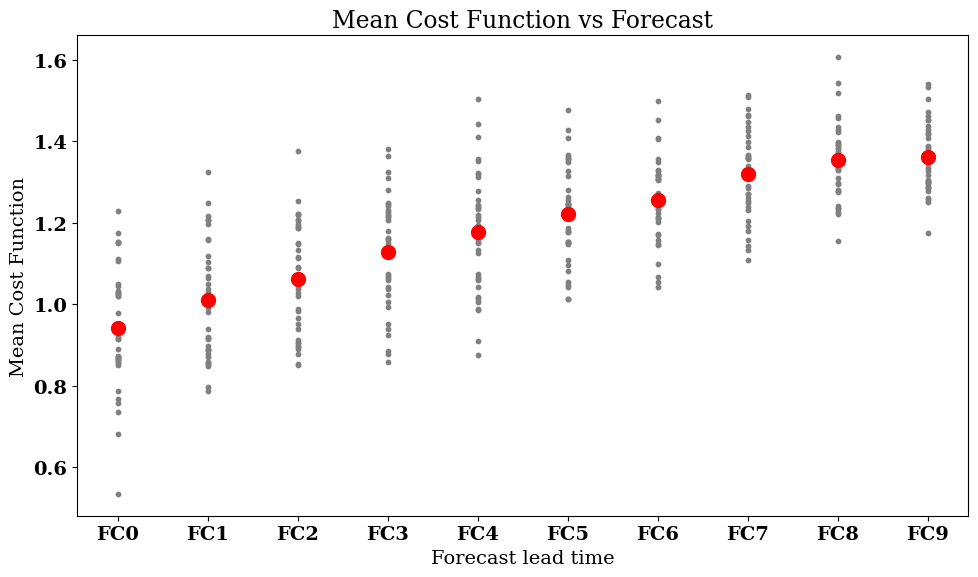

In [117]:
# Nombre de p�riodes de pr�vision (FC0 � FC9)
num_forecasts = len(results['MEAN'])

# Cr�ation du scatter plot
plt.figure(figsize=(10, 6))
for fc_idx in range(num_forecasts):
    for day_idx in range(len(results['MEAN'][fc_idx])):
        plt.scatter(fc_idx, results['MEAN'][fc_idx][day_idx], color='grey', s=10)

# Calcul de la moyenne pour chaque p�riode de pr�vision
mean_values = [np.mean(results['MEAN'][i]) for i in range(num_forecasts)]

# Ajout des points rouges pour la moyenne de chaque p�riode de pr�vision
plt.scatter(range(num_forecasts), mean_values, color='red', label='Mean', marker='o', s=100)

# Personnalisation du graphique
plt.xlabel('Forecast lead time')
plt.ylabel('Mean Cost Function')
plt.title('Mean Cost Function vs Forecast')
plt.xticks(range(num_forecasts), [f'FC{i}' for i in range(num_forecasts)])  
plt.grid(False)
plt.tight_layout()
plt.show()

In [105]:
import numpy as np
from datetime import datetime, timedelta

input_dir = '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/nrt/GLO12V4/Detect_eddies_2023_SE70/'
input_dirs_FC = [
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_0/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_1/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_2/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_3/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_4/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_5/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_6/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_7/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_8/',
    '/data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_9/',
]

# Initialize lists to store results for each forecast directory
results = {
    'AC': [[] for _ in input_dirs_FC],
    'CC': [[] for _ in input_dirs_FC],
    'MEAN': [[] for _ in input_dirs_FC]
}

# Initialize lists to store scores for each forecast directory
Hits = [[] for _ in input_dirs_FC]
Misses = [[] for _ in input_dirs_FC]
Falarms = [[] for _ in input_dirs_FC]
POD = [[] for _ in input_dirs_FC]
SR = [[] for _ in input_dirs_FC]

start_date = datetime.strptime("20230510", "%Y%m%d")
num_days = 37

for i in range(num_days):
    # Date courante
    date = start_date + timedelta(days=i)
    date_str = date.strftime("%Y%m%d")
    print(date_str)
    
    # Path for the observation files for anticyclones and cyclones
    obs_file_AC = input_dir + f"Anticyclonic_GLO12_{date_str}.nc"
    obs_file_CC = input_dir + f"Cyclonic_GLO12_{date_str}.nc"
    
    # Load observation data
    obs_data_AC = EddiesObservations.load_file(obs_file_AC)
    obs_data_CC = EddiesObservations.load_file(obs_file_CC)

    for idx, input_dir_FC in enumerate(input_dirs_FC):
        # Path for the forecast files for anticyclones and cyclones
        fcst_file_AC = input_dir_FC + f"Anticyclonic_GLO12_FC0_{date_str}.nc"
        fcst_file_CC = input_dir_FC + f"Cyclonic_GLO12_FC0_{date_str}.nc"
        
        # Load forecast data
        fcst_data_AC = EddiesObservations.load_file(fcst_file_AC)
        fcst_data_CC = EddiesObservations.load_file(fcst_file_CC)
        
        # Calculate tracking and cost for anticyclones
        ref_id_AC, model_id_AC, cost_AC = obs_data_AC.tracking(fcst_data_AC)
        mean_cost_AC = np.mean(cost_AC)
        results['AC'][idx].append(mean_cost_AC)
        
        # Calculate tracking and cost for cyclones
        ref_id_CC, model_id_CC, cost_CC = obs_data_CC.tracking(fcst_data_CC)
        mean_cost_CC = np.mean(cost_CC)
        results['CC'][idx].append(mean_cost_CC)
        
        # Calculate mean cost
        mean_cost = (mean_cost_AC + mean_cost_CC) / 2
        results['MEAN'][idx].append(mean_cost)

        # Calculate Hits, Misses, and False Alarms for anticyclones
        reference_id_AC_junk, model_id_AC_junk = reverse_index(ref_id_AC, len(obs_data_AC)), reverse_index(model_id_AC, len(fcst_data_AC))
        
        hits_AC = len(ref_id_AC)
        misses_AC = len(reference_id_AC_junk)
        falarms_AC = len(model_id_AC_junk)

        # Calculate Hits, Misses, and False Alarms for cyclones
        reference_id_CC_junk, model_id_CC_junk = reverse_index(ref_id_CC, len(obs_data_CC)), reverse_index(model_id_CC, len(fcst_data_CC))
        
        hits_CC = len(ref_id_CC)
        misses_CC = len(reference_id_CC_junk)
        falarms_CC = len(model_id_CC_junk)

        # Sum Hits, Misses, and False Alarms
        total_hits = hits_AC + hits_CC
        total_misses = misses_AC + misses_CC
        total_falarms = falarms_AC + falarms_CC

        # Append to results lists
        Hits[idx].append(total_hits)
        Misses[idx].append(total_misses)
        Falarms[idx].append(total_falarms)
        POD[idx].append(total_hits / (total_hits + total_misses) if total_hits + total_misses > 0 else np.nan)
        SR[idx].append(1 - (total_falarms / (total_hits + total_falarms) if total_hits + total_falarms > 0 else np.nan))

# Output results for verification
for idx, input_dir_FC in enumerate(input_dirs_FC):
    print(f"Results for {input_dir_FC}:")
    print("Anticyclones:", results['AC'][idx])
    print("Cyclones:", results['CC'][idx])
    print("Mean:", results['MEAN'][idx])

# Output results for Hits, Misses, FA, POD, SR for each forecast directory
for idx, input_dir_FC in enumerate(input_dirs_FC):
    print(f"Scores for {input_dir_FC}:")
    print("Hits:", Hits[idx])
    print("Misses:", Misses[idx])
    print("False Alarms:", Falarms[idx])
    print("Probability of Detection (POD):", POD[idx])
    print("Success Ratio (SR):", SR[idx])


20230510


High number of conflict : 192 (nb_conflict)
One observation have 6 links
High number of conflict : 250 (nb_conflict)
High number of conflict : 190 (nb_conflict)
One observation have 6 links
High number of conflict : 250 (nb_conflict)
One observation have 6 links
High number of conflict : 189 (nb_conflict)
One observation have 6 links
High number of conflict : 256 (nb_conflict)
High number of conflict : 183 (nb_conflict)
One observation have 6 links
High number of conflict : 251 (nb_conflict)
High number of conflict : 190 (nb_conflict)
One observation have 6 links
High number of conflict : 252 (nb_conflict)
High number of conflict : 188 (nb_conflict)
One observation have 6 links
High number of conflict : 245 (nb_conflict)
One observation have 7 links
High number of conflict : 194 (nb_conflict)
One observation have 6 links
High number of conflict : 251 (nb_conflict)
One observation have 6 links
High number of conflict : 182 (nb_conflict)
One observation have 6 links
High number of confli

20230511


High number of conflict : 206 (nb_conflict)
One observation have 6 links
High number of conflict : 239 (nb_conflict)
One observation have 6 links
High number of conflict : 195 (nb_conflict)
One observation have 6 links
High number of conflict : 228 (nb_conflict)
One observation have 6 links
High number of conflict : 201 (nb_conflict)
One observation have 6 links
High number of conflict : 234 (nb_conflict)
One observation have 6 links
High number of conflict : 205 (nb_conflict)
One observation have 6 links
High number of conflict : 227 (nb_conflict)
One observation have 6 links
High number of conflict : 199 (nb_conflict)
One observation have 6 links
High number of conflict : 232 (nb_conflict)
One observation have 6 links
High number of conflict : 190 (nb_conflict)
One observation have 6 links
High number of conflict : 220 (nb_conflict)
One observation have 6 links
High number of conflict : 203 (nb_conflict)
One observation have 6 links
High number of conflict : 230 (nb_conflict)
One obs

20230512


...

20230614


One observation have 6 links
One observation have 6 links
High number of conflict : 184 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 189 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 175 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 175 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 175 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 175 (nb_conflict)
One observation have 6 links
One observation have 6 links
High number of conflict : 182 (nb_conflict)
One observation have 6 links
High number of conflict : 212 (nb_conflict)
One observation have 6 links
High number of conflict : 206 (nb_conflict)
One observation have 6 links
High number of conflict : 199 (nb_conflict)


20230615


High number of conflict : 129 (nb_conflict)
High number of conflict : 197 (nb_conflict)
High number of conflict : 208 (nb_conflict)
High number of conflict : 199 (nb_conflict)
High number of conflict : 200 (nb_conflict)
High number of conflict : 200 (nb_conflict)
High number of conflict : 200 (nb_conflict)
High number of conflict : 200 (nb_conflict)
One observation have 6 links
High number of conflict : 192 (nb_conflict)
High number of conflict : 204 (nb_conflict)


Results for /data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_0/:
Anticyclones: [1.1489226351079254, 0.7021490026403356, 0.8211065756308066, 0.8268164225987026, 0.982089498768682, 0.8148036684308734, 1.032733197482127, 0.9233216961610664, 0.7043776024044968, 0.6706052950727261, 0.8208946954636347, 0.9722347582800913, 0.9245188529031318, 0.9859819083378233, 1.2781140362774883, 0.8078152229046, 0.8711471557617188, 0.9821016327673647, 0.842962866430884, 0.9122215196924303, 1.1147461678217916, 1.1580436343238467, 0.90763977595738, 1.012774966178684, 1.1861298060653234, 1.0903704217139711, 1.057378395316527, 1.0632364508811007, 1.0864837981842377, 0.9771670717181582, 0.9429710706075033, 0.8188014606853108, 1.1017749987150494, 0.8863321940104166, 0.9798338334638994, 0.9483581354588638, 0.6202649268034462]
Cyclones: [1.200495445122153, 0.833686602557147, 0.8803084402373342, 0.884421169757843, 0.8493262002634447, 0.9191971477280315, 1.2718024715300529

In [106]:
for idx, input_dir_FC in enumerate(input_dirs_FC):
    print(f"Scores for {input_dir_FC}:")
    print("Hits:", Hits[idx])
    print("Misses:", Misses[idx])
    print("False Alarms:", Falarms[idx])
    print("Probability of Detection (POD):", POD[idx])
    print("Success Ratio (SR):", SR[idx])

Scores for /data/rd_exchange/fdubost/EddyDetection/FDUBOST/FORECAST/GLO12/fcst_all/Detect_eddies_GLO_FC_0/:
Hits: [215, 243, 243, 240, 244, 229, 230, 241, 260, 265, 269, 251, 241, 239, 235, 262, 259, 259, 243, 225, 218, 220, 230, 227, 220, 210, 212, 200, 201, 221, 216, 209, 212, 207, 201, 191, 235]
Misses: [56, 24, 33, 40, 45, 55, 62, 63, 33, 32, 28, 44, 60, 49, 48, 30, 30, 34, 54, 43, 54, 45, 37, 27, 31, 36, 36, 38, 44, 26, 17, 37, 32, 38, 41, 43, 7]
False Alarms: [58, 34, 36, 38, 39, 44, 47, 46, 35, 29, 32, 34, 38, 36, 39, 27, 30, 29, 29, 43, 43, 51, 29, 42, 36, 40, 45, 62, 57, 21, 24, 29, 36, 36, 37, 37, 17]
Probability of Detection (POD): [0.7933579335793358, 0.9101123595505618, 0.8804347826086957, 0.8571428571428571, 0.8442906574394463, 0.8063380281690141, 0.7876712328767124, 0.7927631578947368, 0.8873720136518771, 0.8922558922558923, 0.9057239057239057, 0.8508474576271187, 0.8006644518272426, 0.8298611111111112, 0.8303886925795053, 0.8972602739726028, 0.8961937716262975, 0.883959

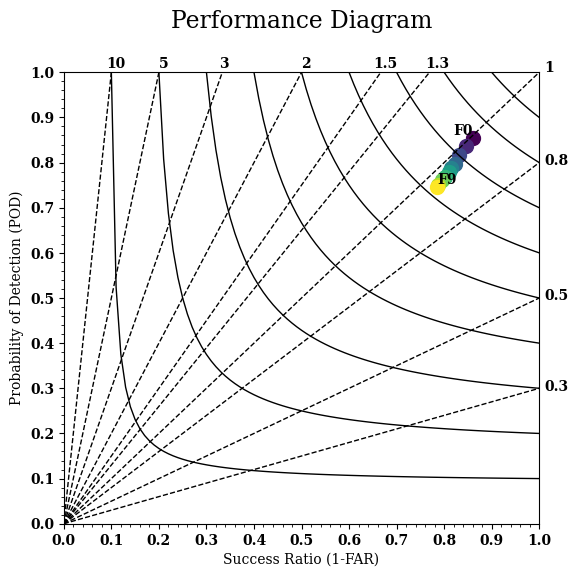

In [132]:
CSI = np.arange(0.1, 1, 0.1)
xvals = [0.57, 0.62, 0.77, 0.79, 0.85, 0.9, 0.95, 0.935, 0.96]
labels = ["0.3", "0.5", "0.8", "1", "1.3", "1.5", "2", "3", "5", "10"]


fig, ax = plt.subplots(figsize=(6, 6))

# Plot CSI
for c in CSI:
    i = np.arange(0, 1.1, 0.01)
    y = (c * i) / (c * i - c + i)
    indices = np.where(y <= 0.0)
    y = np.delete(y, indices)
    i = np.delete(i, indices)
    ax.plot(i, y, color="k", linewidth=1, label=str(np.round(c, 2)))

x = [1.01, 1.01, 1.01, 1.01, 0.76, 0.65, 0.5, 0.327, 0.2, 0.09]
y_offsets = [0.295, 0.495, 0.795, 1, 1.01, 1.01, 1.01, 1.01, 1.01, 1.01]
pente = np.arange(0, 1.1, 0.1)
for i, label in enumerate(labels):
    ax.plot(pente, pente * float(label), linestyle="--", color="k", linewidth=1)
    ax.text(x[i], y_offsets[i], label, size=10)


colors = plt.cm.viridis(np.linspace(0, 1, 10))
for idx in range(10):
    ax.scatter(np.mean(SR[idx]), np.mean(POD[idx]), color=colors[idx], s=100, label=f'F{idx}')

ax.text(np.mean(SR[0]), np.mean(POD[0]), "F0", fontsize=10, ha='right', va='bottom')
ax.text(np.mean(SR[-1]), np.mean(POD[-1]), "F9", fontsize=10, ha='left', va='bottom')

ax.set_title("Performance Diagram", y=1.08)
ax.set_xlabel("Success Ratio (1-FAR)", fontsize=10)
ax.set_ylabel("Probability of Detection (POD)", fontsize=10)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xticks(np.arange(0, 1.1, step=0.1))
ax.set_yticks(np.arange(0, 1.1, step=0.1))
ax.tick_params(axis="both", which="both", labelsize=10)
ax.minorticks_on()


plt.tight_layout()
plt.show()
